# Homework 2

In this report, we will process data from 3 datasets:
* Apartment prices in Ekhagen (`data/Booli_sold.csv`),
* Voting in the 2018 election in Sweden (`data/2018_R_per_kommun.csv`),
* Stroke data (`data/stroke-data.csv`).

From this data we will compute certain values of interest and investigate some noteworthy relationships.


Don't forget to run `pip install -r environment/requirements.txt` before running code in this file.

<br>

---

### Task A: Apartment Prices (Ekhagen)

Let's start by loading in the dataset and previewing the first few rows.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


apartment_sales = pd.read_csv("data/Booli_sold.csv")

apartment_sales.head()


,listPrice,rent,livingArea,rooms,published,constructionYear,objectType,booliId,soldDate,soldPrice,...,location.position.latitude,location.position.longitude,location.position.isApproximate,location.region.municipalityName,location.region.countyName,location.distance.ocean,source.name,source.id,source.type,source.url
0,3995000,4467.0,73.0,3.0,2018-10-15 13:33:18,1935.0,Lägenhet,3263989,2018-11-08,3820000,...,59.371033,18.054057,NaN,Stockholm,Stockholms län,260,MOHV,1901865,Broker,http://www.mohv.se/
1,1995000,1773.0,36.0,1.0,2018-10-05 14:29:28,1968.0,Lägenhet,3256231,2018-10-19,2355000,...,59.371242,18.057821,NaN,Stockholm,Stockholms län,218,Notar,1566,Broker,http://www.notar.se/
2,5100000,3839.0,81.0,3.0,2018-09-11 13:44:43,1936.0,Lägenhet,3236660,2018-09-27,6110000,...,59.371617,18.054716,NaN,Stockholm,Stockholms län,186,Historiska Hem AB,65645750,Broker,http://historiskahem.se/
3,5495000,4483.0,107.0,4.0,2018-08-25 02:56:56,1936.0,Lägenhet,3224374,2018-09-06,8050000,...,59.371480,18.053880,NaN,Stockholm,Stockholms län,218,Notar,1566,Broker,http://www.notar.se/
4,1995000,1696.0,29.0,1.0,2018-06-15 17:16:19,1936.0,Lägenhet,3185496,2018-06-18,2400000,...,59.372160,18.053542,True,Stockholm,Stockholms län,166,Mäklarhuset,204,Broker,http://www.maklarhuset.se/


1\. First of all, we want to add a new column, `"ppsqm"` (price per square metre),
which we will calculate by dividing the price the apartment sold for (`"soldPrice"`)
by the living area (`"livingArea"`).

We can then view these quantities for the first few rows of the table
to check that they seem correct.

In [2]:
apartment_sales["ppsqm"] = apartment_sales["soldPrice"] / apartment_sales["livingArea"]
apartment_sales[["soldPrice", "livingArea", "ppsqm"]].head()

,soldPrice,livingArea,ppsqm
0,3820000,73.0,52328.767123
1,2355000,36.0,65416.666667
2,6110000,81.0,75432.098765
3,8050000,107.0,75233.644860
4,2400000,29.0,82758.620690


One apartment has a `"livingArea"` of `NaN`, which leads to it having a `"ppsqm"` of `NaN`,
which seems like a reasonable and desirable outcome. There are no apartments with a `"livingArea"` of 0,
so we don't need to handle this edge case.

<br>

---

2\. Now we want to display a few select columns of the 5 apartments with the highest values for `"ppsqm"`.

In [3]:
apartment_sales.sort_values("ppsqm", ascending=False)[["location.address.streetAddress", "livingArea", "soldPrice", "ppsqm"]].head()

,location.address.streetAddress,livingArea,soldPrice,ppsqm
67,Ekhagsvägen 8,24.0,2500000,104166.666667
50,Ekhagsvägen 8,24.0,2450000,102083.333333
54,Ekhagsvägen 10,23.0,2300000,100000.000000
34,Torphagsvägen 4,25.0,2210000,88400.000000
55,Docentbacken 1B,26.9,2300000,85501.858736


---

3\. Next, we want to calculate the mean price per square metre.

`DataFrame.mean()` has a `skipna` parameter (that defaults to `True`)
that means `NaN` values are ignored when calculating the mean, which is what we want.

We also want to check that there aren't large outliers that might be disproportionally
impacting the mean. Let's have a look at a box plot to see what the data looks like.

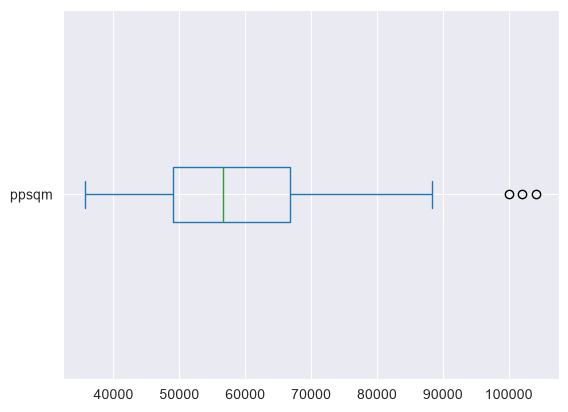

In [4]:
apartment_sales["ppsqm"].plot.box(vert=False)
plt.show()

According to the documentation, the whiskers of the box plot are
to the furthest point within 1.5 IQRs (interquartile ranges) of the edges
of the IQR box. Values outside of this are commonly considered outliers.

Looking at the box plot, it appears we have 3 outliers by this metric,
although they are not completely unreasonable and are still firmly
within the same order of magnitude.

Let's first calculate the mean including these points:

In [5]:
apartment_sales["ppsqm"].mean()

np.float64(58759.382760081724)

which gives us a mean of $\bar{x} \approx 58759 \text{ kr}$ per square metre.

If we instead calculate the mean excluding these outliers:



In [6]:
lower_quartile = apartment_sales["ppsqm"].quantile(0.25)
upper_quartile = apartment_sales["ppsqm"].quantile(0.75)
iqr = upper_quartile - lower_quartile
mask = apartment_sales["ppsqm"].between(lower_quartile - 1.5*iqr, upper_quartile + 1.5*iqr)
apartment_sales["ppsqm"].filter(cond=mask).mean()

np.float64(57915.40969696643)

which gives us a mean of $\bar{x} \approx 57915 \text{ kr}$ per square metre.

This number differs from our previous value by about 1.4%, which isn't much.
However, I do not think it is fair to exclude these points as outliers.
They are somewhat higher than expected, but they represent real data that is still within reason.

I therefore think it is reasonable to draw the conclusion that our first value for the mean,
$\bar{x} \approx 58759 \text{ kr}$ is the correct one to use.

<br>

---

4\. Finally, let's find an interesting aspect of the data to talk about.
Let's investigate how an apartment's price per square metre varies based on its living area.

We can create a scatter plot of price per square metre against living area to see this visually,
along with a line of best fit. The `seaborn.regplot()` function suits this purpose well.

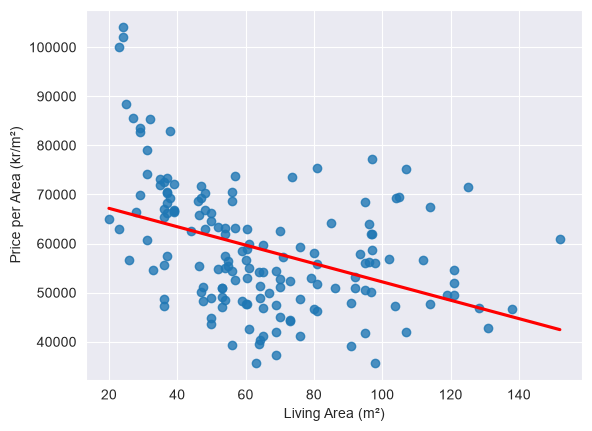

In [7]:
sns.regplot(data=apartment_sales, x="livingArea", y="ppsqm", ci=None, line_kws={"color": "red"})
plt.xlabel("Living Area (m²)")
plt.ylabel("Price per Area (kr/m²)")
plt.show()

The graph seems to show a negative correlation between living area and price per square metre.
We can check the correlation coefficient between these two quantities using the `.corr()`
method, so we don't have to rely on our (somewhat subjective)
visual interpretation of the data to draw a conclusion.

In [8]:
apartment_sales["livingArea"].corr(apartment_sales["ppsqm"])

np.float64(-0.4083300973740849)

This shows us a correlation coefficient of $r \approx -0.408$,
which indicates a moderate negative correlation between the two quantities.

A plausible explanation for this is that apartments in expensive areas
(and thus higher price per square metre) are likely smaller in general,
in order to make them affordable.
There may also be a base cost to an apartment that is fixed regardless of its size.

<br>

---


### Task B: Swedish Election 2018

Let's again begin by loading the dataset and previewing the first few rows.
We need to specify the delimiter as `";"` and the decimal indicator as `","`,
since these are not the defaults for csv files.

In [9]:
votes = pd.read_csv("data/2018_R_per_kommun.csv", delimiter=";", decimal=",")
votes.head()

,LÄNSKOD,KOMMUNKOD,LÄNSNAMN,KOMMUNNAMN,M,C,L,KD,S,V,...,TRP,VL-S,ÖVR,OGEJ,BLANK,OG,RÖSTER GILTIGA,RÖSTANDE,RÖSTBERÄTTIGADE,VALDELTAGANDE
0,1,14,Stockholms län,Upplands Väsby,23.11,6.26,5.66,6.71,26.97,8.01,...,NaN,NaN,NaN,0.04,0.69,0.06,25830,26036,30740,84.70
1,1,15,Stockholms län,Vallentuna,28.29,10.11,7.73,7.58,18.91,4.47,...,0.0,NaN,0.00,0.02,0.59,0.08,20952,21099,23438,90.02
2,1,17,Stockholms län,Österåker,29.68,9.35,7.48,7.13,19.71,4.97,...,NaN,NaN,0.01,0.03,0.69,0.13,27711,27947,31309,89.26
3,1,20,Stockholms län,Värmdö,27.49,9.76,6.40,5.89,20.48,6.02,...,NaN,NaN,0.01,0.04,0.67,0.07,28115,28335,31371,90.32
4,1,23,Stockholms län,Järfälla,23.96,6.31,6.04,6.29,27.68,8.75,...,0.0,NaN,0.02,0.04,0.53,0.07,45654,45948,53230,86.32


1\. We want to count the total number of legitimate votes across all Stockholm municipalities.
In order to do this, we need to filter for the data so that we only have municipalities
that are within Stockholm (we will filter for `LÄNSNAMN == "Stockholms län"`), and then
sum their `"RÖSTER GILTIGA"` columns.

In [10]:
votes.filter(cond=votes["LÄNSNAMN"] == "Stockholms län")["RÖSTER GILTIGA"].sum()

np.int64(1426237)

We see that there were 1426237 legitimate votes in Stockholm in 2018.

<br>

---

2\. Now we want to find the municipality with the highest vote percentage for Socialdemokraterna (S).
To do this, we can sort municipalities by their `S` vote percentage in descending order, and see which one is highest.

In [11]:
votes.sort_values("S", ascending=False).head(1)

,LÄNSKOD,KOMMUNKOD,LÄNSNAMN,KOMMUNNAMN,M,C,L,KD,S,V,...,TRP,VL-S,ÖVR,OGEJ,BLANK,OG,RÖSTER GILTIGA,RÖSTANDE,RÖSTBERÄTTIGADE,VALDELTAGANDE
188,17,62,Värmlands län,Munkfors,8.33,8.12,2.91,3.93,52.18,6.11,...,NaN,NaN,NaN,NaN,1.02,NaN,2340,2364,2777,85.13


We see that *Munkfors* had the highest vote for Socialdemokraterna with 52.18%.

<br>

---

3\. Finally, we want to produce a table showing the top 3 municipalities by voter turnout (valdeltagande).

We can do this in a similar way; sorting by the `"VALDELTAGANDE"` column in descending order,
then displaying the first 3 rows.

In [12]:
votes.sort_values("VALDELTAGANDE", ascending=False)[["KOMMUNNAMN", "VALDELTAGANDE"]].head(3)

,KOMMUNNAMN,VALDELTAGANDE
103,Lomma,93.86
59,Habo,93.35
98,Vellinge,93.13


---

### Task C: Predicting Strokes

Let us yet again load and preview the data.

In [13]:
strokes = pd.read_csv("data/stroke-data.csv")
strokes.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


Let's make a box plot of glucose levels for people who didn't and did have a stroke respectively.

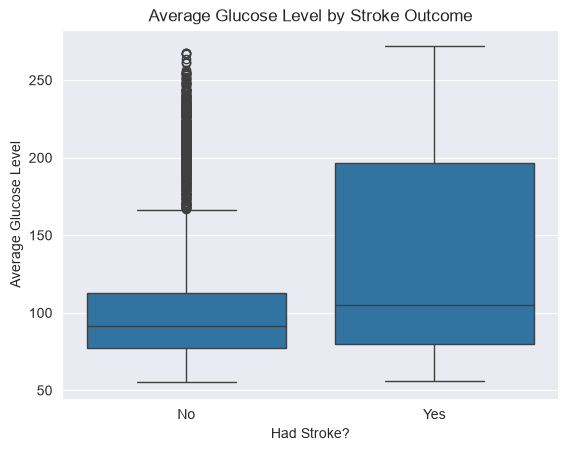

In [14]:
sns.boxplot(strokes, x="stroke", y="avg_glucose_level")
plt.xticks([0, 1], ["No", "Yes"])
plt.xlabel("Had Stroke?")
plt.ylabel("Average Glucose Level")
plt.title("Average Glucose Level by Stroke Outcome")
plt.show()

Let's also calculate the medians precisely so we can discuss them.

In [15]:
strokes.groupby("stroke")["avg_glucose_level"].median()

stroke
0     91.47
1    105.22
Name: avg_glucose_level, dtype: float64

We see from the box plot that average glucose levels tend to be higher amongst people who
had a stroke (median 105) compared with people who did not have a stroke (median 91).

<br>

---

### Conclusion

* The average price per square metre of apartments sold in the dataset was 58759 kr. Price per square metre was negatively correlated with apartment size ($r=-0.408$).
* Munkfors had the highest vote share for Socialdemokraterna in the 2018 election. Lomma, Habo, and Vellinge (in that order) had the highest voter turnout.
* Average glucose levels appear to be higher amongst stroke victims.